# Solar filament segmentation: end-to-end demo

Runs one of the two final pipelines on the test H-alpha frames from the released weights, writes the submission
CSV and shows the predicted filaments on the frames.

Pipeline (`final/<pick>.json`): dense U-Net ensemble (5 fold models per run, 8-fold TTA) -> connected-component
candidates -> LightGBM scorer -> crop refiner -> CNN rescorer -> keep candidates with mean(scorer, rescorer) > tau ->
pixel-disjoint masks. Paths come from the environment (`FIL_DATA`, `FIL_WEIGHTS`, `FIL_WORK`) or the defaults below.
For the 180 test frames s15 takes about 21 min on two H200s (40 min on one), s16 about 12 min on one H200
(32 min on an RTX 3090). The run below is s15 on two H200s; `SUBMITTED` compares the result with the CSV we submitted.

In [1]:
import json, os, time
PICK = os.environ.get("PICK", "s15")                       # "s15" (teacher ensemble) or "s16" (distilled students)
os.environ.setdefault("FIL_DATA", "data")                  # folder with train/ and test/ from Kaggle
os.environ.setdefault("FIL_WEIGHTS", "weights")            # released weights (final/weights_manifest.csv)
os.environ.setdefault("FIL_WORK", "work_demo")             # everything the pipeline writes
SUBMITTED = os.environ.get("SUBMITTED", "")                # optional: the CSV submitted to Kaggle, for comparison
OUT = f"submission_{PICK}.csv"

from filseg import pipeline, submission, compare
from filseg.paths import P
cfg = json.load(open(f"final/{PICK}.json"))
print(cfg["summary"])
print("frames:", P.images, "| weights:", P.weights, "| work:", P.work)

teacher ensemble ensB -> LightGBM scorer -> crop refiner (0.5) -> score = mean(LGB, mean of 3 CNN rescorers) > 0.22
frames: data/test/test_images | weights: weights | work: work_demo


In [2]:
t0 = time.time()
import torch
gpus = list(range(torch.cuda.device_count())) or [0]   # the dense stage uses every visible GPU
pipeline.run(cfg, "test", out=OUT, gpus=gpus)
print(f"total {time.time() - t0:.0f} s")
for line in open(os.path.join(P.work, "timings.jsonl")):
    r = json.loads(line)
    if r["config"] == PICK and r["split"] == "test":
        print(f"  {r['stage']:15s} {r['seconds']:8.1f} s")

e10_effv2m_c1536 test f1: 180 maps in 48s (tu-tf_efficientnetv2_m.in21k_ft_in1k, bf16, norm z, tta 8)
e10_effv2m_c1536 test f0: 180 maps in 48s (tu-tf_efficientnetv2_m.in21k_ft_in1k, bf16, norm z, tta 8)


e10_effv2m_c1536 test f2: 180 maps in 46s (tu-tf_efficientnetv2_m.in21k_ft_in1k, bf16, norm z, tta 8)
e10_effv2m_c1536 test f3: 180 maps in 47s (tu-tf_efficientnetv2_m.in21k_ft_in1k, bf16, norm z, tta 8)


e10_effv2m_c1536 test f4: 180 maps in 46s (tu-tf_efficientnetv2_m.in21k_ft_in1k, bf16, norm z, tta 8)
e7_tta8 test f0: 180 maps in 46s (tu-tf_efficientnetv2_m.in21k_ft_in1k, bf16, norm z, tta 8)


e7_tta8 test f1: 180 maps in 46s (tu-tf_efficientnetv2_m.in21k_ft_in1k, bf16, norm z, tta 8)


e7_tta8 test f2: 180 maps in 46s (tu-tf_efficientnetv2_m.in21k_ft_in1k, bf16, norm z, tta 8)


e7_tta8 test f3: 180 maps in 46s (tu-tf_efficientnetv2_m.in21k_ft_in1k, bf16, norm z, tta 8)


... (52 outputs left out)

[s15 test] rescorer: 9s


wrote submission_s15.csv: 1157 filaments on 179 frames


[s15 test] assemble: 7s


total 1248 s
  maps              1113.6 s
  candidates          45.3 s
  crops               37.7 s
  extra_channels      28.8 s
  refiner              2.8 s
  rescorer             8.7 s
  assemble             6.9 s


In [3]:
from filseg.common import list_stems
rows = submission.read_csv(OUT)
submission.validate(rows, set(list_stems(P.images)))
frames = submission.by_frame(rows)
print(f"{OUT}: {len(rows)} filaments on {len(frames)} of {len(list_stems(P.images))} frames (valid, pixel-disjoint)")
if SUBMITTED and os.path.exists(SUBMITTED):
    compare.compare_csv(OUT, SUBMITTED)

submission_s15.csv: 1157 filaments on 179 of 180 frames (valid, pixel-disjoint)
rows_a                 1157
rows_b                 1157
frames                 179
identical_frames       74
identical_filaments    986
matched                1157
unmatched_a            0
unmatched_b            0
mean_iou_matched       0.9997955648319049
min_iou_matched        0.9525347110106555
pq_a_vs_b              0.9997955648319051
byte_identical         False


## Predicted filaments on H-alpha frames
Each colour is one predicted filament (outline); the right panel is the ensemble probability map.

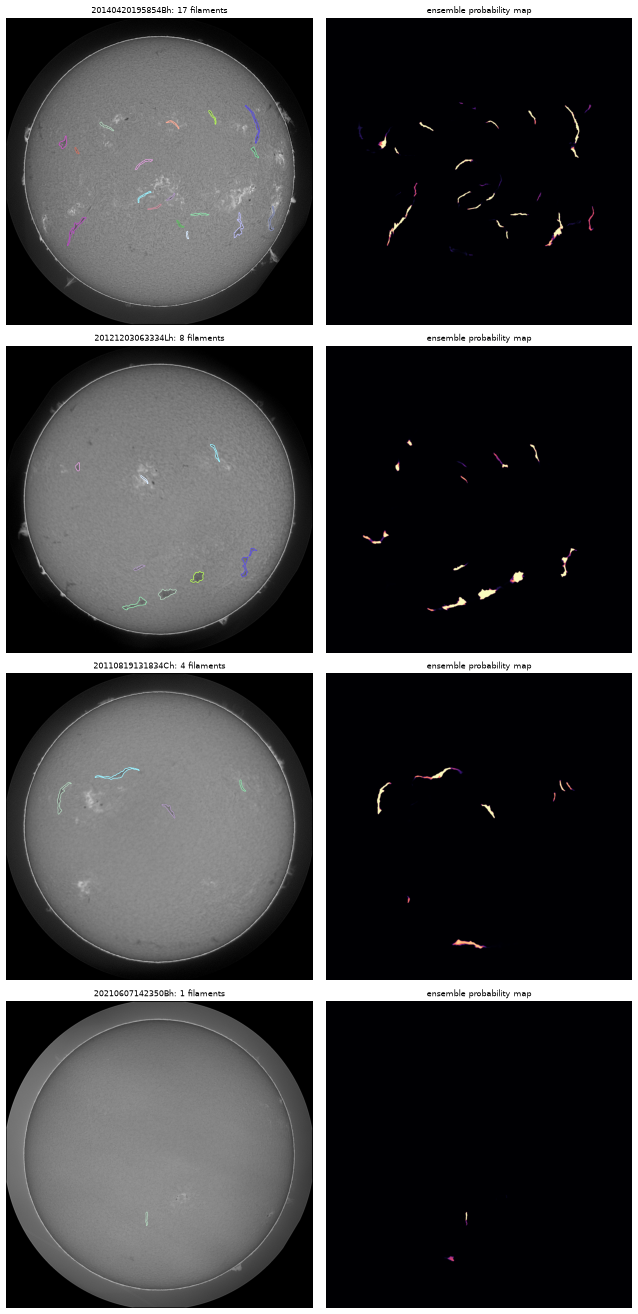

In [4]:
import numpy as np, matplotlib.pyplot as plt
plt.rcParams["figure.dpi"] = 60
from pycocotools import mask as mu
from filseg.common import load_img
from filseg.candidates import ensemble_map

def show(stem, ax_img, ax_map):
    im = load_img(stem, test=True)
    ax_img.imshow(im, cmap="gray", vmin=0, vmax=255)
    rng = np.random.RandomState(0)
    for r in frames.get(stem, []):
        m = mu.decode(r)
        ax_img.contour(m, levels=[0.5], colors=[rng.uniform(0.3, 1, 3)], linewidths=0.9)
    ax_img.set_title(f"{stem}: {len(frames.get(stem, []))} filaments", fontsize=9)
    ax_map.imshow(ensemble_map(stem, cfg["ensemble"], "test"), cmap="magma", vmin=0, vmax=255)
    ax_map.set_title("ensemble probability map", fontsize=9)
    for a in (ax_img, ax_map):
        a.axis("off")

stems = sorted(frames, key=lambda s: -len(frames[s]))
pick = [stems[0], stems[len(stems) // 3], stems[2 * len(stems) // 3], stems[-1]]
fig, axes = plt.subplots(len(pick), 2, figsize=(11, 5.5 * len(pick)))
for s, (a, b) in zip(pick, axes):
    show(s, a, b)
plt.tight_layout(); plt.show()

Zoom on the frame with the most filaments:

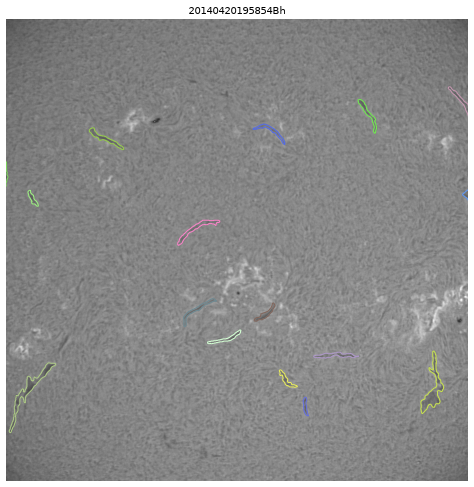

In [5]:
s = stems[0]
im = load_img(s, test=True)
fig, ax = plt.subplots(figsize=(10, 10))
ax.imshow(im[400:1650, 400:1650], cmap="gray", vmin=0, vmax=255, extent=(400, 1650, 1650, 400))
rng = np.random.RandomState(1)
for r in frames[s]:
    ax.contour(np.arange(2048), np.arange(2048), mu.decode(r), levels=[0.5], colors=[rng.uniform(0.3, 1, 3)], linewidths=1.2)
ax.set_xlim(400, 1650); ax.set_ylim(1650, 400); ax.axis("off"); ax.set_title(s)
plt.show()